# 最终 V3 主模型与机器学习支持证据

本 notebook 用来落实本项目最终的建模策略：

- **V3 operation-aware statistical baseline** 作为最终/主异常检测模型。
- **Optimized Isolation Forest** 作为主要的无监督机器学习支持模型。
- **LOF** 作为额外的无监督学习对照和支持模型。

最终异常标签和异常事件由 V3 决定。IF 和 LOF 不替代最终模型，而是为 V3 事件提供跨模型支持证据，用于验证、排序和解释异常事件。

## Cell 1：设置路径、参数和必要输入

这个 cell 用来准备 notebook 的运行环境。它会导入所需 Python 库，定位项目目录，定义输出目录，并设置后续判断 IF/LOF 是否有效支持某个 V3 事件的阈值。

**这里会检查的输入文件：**

- V3 异常事件表
- V3 long score 表
- Optimized Isolation Forest 完整结果表
- LOF 完整结果表
- 优化版方法选择 summary

**这里创建的输出目录：** `outputs/floor6_zone1245_final_v3_with_ml_support/` 以及其中的 `charts/` 子目录。

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, SVG, display


def locate_project_dir() -> Path:
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "Artificial Intelligence for Smart-Building Log Analysis",
        *cwd.parents,
        *[parent / "Artificial Intelligence for Smart-Building Log Analysis" for parent in cwd.parents],
    ]
    for candidate in candidates:
        if (candidate / "outputs").exists() and (candidate / "ml").exists():
            return candidate
    raise FileNotFoundError("Cannot locate project directory")


PROJECT_DIR = locate_project_dir()
OUTPUT_DIR = PROJECT_DIR / "outputs" / "floor6_zone1245_final_v3_with_ml_support"
CHART_DIR = OUTPUT_DIR / "charts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

KEY_COLUMNS = ["timestamp", "floor", "zone"]
MIN_MEANINGFUL_SUPPORT_POINTS = 5
MIN_MEANINGFUL_SUPPORT_PCT = 5.0

V3_EVENTS_PATH = (
    PROJECT_DIR
    / "outputs/floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware"
    / "baseline_tables/11_baseline_anomaly_events.csv"
)
V3_SCORE_PATH = (
    PROJECT_DIR
    / "outputs/floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware"
    / "baseline_tables/09_baseline_anomaly_scores_long.csv.gz"
)
IF_RESULTS_PATH = PROJECT_DIR / "outputs/isolation_forest_huaye/if_period_auto_results_full.csv.gz"
LOF_RESULTS_PATH = PROJECT_DIR / "outputs/floor6_zone1245_lof_modelling_gavin/lof_anomaly_results_full.csv.gz"
METHOD_SELECTION_PATH = (
    PROJECT_DIR
    / "outputs/floor6_zone1245_model_method_evaluation_optimized"
    / "method_selection_summary_optimized.json"
)

required_paths = [V3_EVENTS_PATH, V3_SCORE_PATH, IF_RESULTS_PATH, LOF_RESULTS_PATH, METHOD_SELECTION_PATH]
missing = [str(path.relative_to(PROJECT_DIR)) for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Missing required inputs: {missing}")

print(f"Project directory: {PROJECT_DIR}")
print(f"Final model output directory: {OUTPUT_DIR}")
print(f"Meaningful ML support threshold: >= {MIN_MEANINGFUL_SUPPORT_POINTS} points and >= {MIN_MEANINGFUL_SUPPORT_PCT:.1f}% of event minutes")


Project directory: D:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis
Final model output directory: D:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_final_v3_with_ml_support
Meaningful ML support threshold: >= 5 points and >= 5.0% of event minutes


## Cell 2：读取 V3 事件和逐分钟机器学习证据

这个 cell 会读取 V3 异常事件，然后从 Optimized Isolation Forest 输出中读取逐分钟的证据。IF 输出表中已经包含 LOF 标签，但这里仍然单独读取原始 LOF 输出，用来验证 LOF 标签是否仍然能够正确对齐。

**目的：** 确保最终事件级分析使用的 V3、IF 和 LOF 输出是一致的。

**主要展示结果：** 数据加载 summary，包括事件数量、逐分钟行数、异常率、时间范围和 LOF 对齐一致性。

In [2]:
v3_events = pd.read_csv(V3_EVENTS_PATH, parse_dates=["start_time", "end_time"])

row_usecols = [
    "timestamp",
    "floor",
    "zone",
    "hour",
    "operating_period",
    "baseline_anomaly_label",
    "baseline_anomaly_count",
    "baseline_anomaly_methods",
    "baseline_anomaly_variables",
    "baseline_anomaly_directions",
    "period_if_anomaly_label",
    "period_if_anomaly_score",
    "lof_anomaly_label",
    "lof_anomaly_score",
]
row_evidence = pd.read_csv(IF_RESULTS_PATH, usecols=row_usecols, parse_dates=["timestamp"])
if row_evidence.duplicated(KEY_COLUMNS).any():
    raise AssertionError("Row evidence table contains duplicate timestamp/floor/zone keys")

# Keep an independent LOF alignment check. The IF output already carries LOF labels, but this confirms the source still matches.
lof_check = pd.read_csv(
    LOF_RESULTS_PATH,
    usecols=KEY_COLUMNS + ["lof_anomaly_label", "lof_anomaly_score"],
    parse_dates=["timestamp"],
)
lof_compare = row_evidence[KEY_COLUMNS + ["lof_anomaly_label", "lof_anomaly_score"]].merge(
    lof_check,
    on=KEY_COLUMNS,
    how="left",
    suffixes=("_if_table", "_lof_table"),
    validate="one_to_one",
)
if lof_compare[["lof_anomaly_label_lof_table", "lof_anomaly_score_lof_table"]].isna().any().any():
    raise AssertionError("Independent LOF source failed to align with IF row table")
lof_label_agreement = float((lof_compare["lof_anomaly_label_if_table"] == lof_compare["lof_anomaly_label_lof_table"]).mean())

load_summary = pd.DataFrame([
    {
        "v3_event_count": len(v3_events),
        "row_count": len(row_evidence),
        "zone_count": row_evidence["zone"].nunique(),
        "start_time": row_evidence["timestamp"].min(),
        "end_time": row_evidence["timestamp"].max(),
        "row_level_v3_anomaly_rate_pct": 100 * row_evidence["baseline_anomaly_label"].mean(),
        "row_level_if_anomaly_rate_pct": 100 * row_evidence["period_if_anomaly_label"].mean(),
        "row_level_lof_anomaly_rate_pct": 100 * row_evidence["lof_anomaly_label"].mean(),
        "lof_alignment_agreement": lof_label_agreement,
    }
])

display(load_summary.T.rename(columns={0: "value"}))
display(v3_events.head())


,value
v3_event_count,475
row_count,362880
zone_count,4
start_time,2018-07-01 00:00:00
end_time,2018-09-01 23:59:00
row_level_v3_anomaly_rate_pct,12.85797
row_level_if_anomaly_rate_pct,5.0
row_level_lof_anomaly_rate_pct,5.0
lof_alignment_agreement,1.0


,event_id,zone,variable,anomaly_method,anomaly_direction,start_time,end_time,duration_minutes,required_persistence_minutes,operating_periods,non_work_point_pct,mean_actual,mean_baseline,max_abs_robust_z_score,max_score_for_ranking,exceeds_p99_point_pct,mean_deviation,was_missing_point_pct,severity
0,1,1,light_power_kw,low_quantile_threshold,low,2018-08-13 07:30:00,2018-08-13 18:59:00,690,30,"core_work,ramp_down,ramp_up",0.000000,0.000116,3.399870,27.871901,37.566667,0.000000,-3.399754,0.000000,high
1,2,1,light_power_kw,low_quantile_threshold,low,2018-07-30 07:30:00,2018-07-30 18:59:00,690,30,"core_work,ramp_down,ramp_up",0.000000,2.224884,3.399870,21.883309,37.377396,0.000000,-1.174986,0.000000,high
2,3,5,temperature_c,robust_z_score,high,2018-07-30 08:00:00,2018-07-31 06:59:00,1380,30,"core_work,evening_off,night_off,ramp_down",52.173913,29.960696,26.670709,36.593400,36.593400,40.144928,3.289988,1.594203,high
3,4,2,light_power_kw,low_quantile_threshold,low,2018-07-27 07:00:00,2018-07-27 18:59:00,720,30,"core_work,ramp_down,ramp_up",0.000000,0.601587,6.599796,24.268670,31.980891,0.000000,-5.998209,0.000000,high
4,5,5,temperature_c,robust_z_score,high,2018-08-13 13:15:00,2018-08-14 06:59:00,1065,30,"core_work,evening_off,night_off,ramp_down",67.605634,29.259802,27.035660,30.327650,30.327650,0.000000,2.224142,1.502347,high


## Cell 3：为每个 V3 事件添加 IF/LOF 支持证据

这是本 notebook 的核心整合步骤。它会遍历每一个 V3 事件，并查找该事件对应 zone 和时间窗口内的所有逐分钟记录。然后统计这些分钟里有多少同时被 IF 或 LOF 标记为异常。

随后，每个 V3 事件会被分配一个证据等级：

- `v3_with_if_and_lof_support`
- `v3_with_if_support`
- `v3_with_lof_support`
- `v3_primary_only`

**重要设计选择：** V3 仍然是最终模型。IF 和 LOF 只提供支持证据和优先级排序，不决定最终异常标签。

**输出文件：** `01_final_v3_events_with_ml_support.csv`。

In [3]:
def _support_flag(points: int, pct: float) -> bool:
    return points >= MIN_MEANINGFUL_SUPPORT_POINTS and pct >= MIN_MEANINGFUL_SUPPORT_PCT


def classify_evidence(if_supported: bool, lof_supported: bool) -> str:
    if if_supported and lof_supported:
        return "v3_with_if_and_lof_support"
    if if_supported:
        return "v3_with_if_support"
    if lof_supported:
        return "v3_with_lof_support"
    return "v3_primary_only"


def score_evidence_level(level: str) -> int:
    return {
        "v3_primary_only": 1,
        "v3_with_lof_support": 2,
        "v3_with_if_support": 3,
        "v3_with_if_and_lof_support": 4,
    }[level]


row_by_zone = {
    zone: group.sort_values("timestamp").reset_index(drop=True)
    for zone, group in row_evidence.groupby("zone", observed=True)
}

support_rows = []
for event in v3_events.itertuples(index=False):
    zone_rows = row_by_zone.get(event.zone)
    if zone_rows is None:
        raise AssertionError(f"No row evidence found for zone {event.zone}")
    event_rows = zone_rows.loc[
        zone_rows["timestamp"].between(event.start_time, event.end_time, inclusive="both")
    ]
    if event_rows.empty:
        raise AssertionError(f"No row evidence found inside V3 event {event.event_id}")

    total_points = int(len(event_rows))
    if_points = int(event_rows["period_if_anomaly_label"].sum())
    lof_points = int(event_rows["lof_anomaly_label"].sum())
    both_points = int((event_rows["period_if_anomaly_label"].eq(1) & event_rows["lof_anomaly_label"].eq(1)).sum())
    v3_row_points = int(event_rows["baseline_anomaly_label"].sum())
    if_pct = 100 * if_points / total_points if total_points else 0.0
    lof_pct = 100 * lof_points / total_points if total_points else 0.0
    both_pct = 100 * both_points / total_points if total_points else 0.0
    if_supported = _support_flag(if_points, if_pct)
    lof_supported = _support_flag(lof_points, lof_pct)
    level = classify_evidence(if_supported, lof_supported)

    support_rows.append(
        {
            "event_id": event.event_id,
            "event_row_points": total_points,
            "v3_row_overlap_points": v3_row_points,
            "if_support_points": if_points,
            "if_support_pct": if_pct,
            "lof_support_points": lof_points,
            "lof_support_pct": lof_pct,
            "if_and_lof_support_points": both_points,
            "if_and_lof_support_pct": both_pct,
            "if_meaningful_support": if_supported,
            "lof_meaningful_support": lof_supported,
            "ml_support_count": int(if_supported) + int(lof_supported),
            "final_evidence_level": level,
            "final_evidence_rank": score_evidence_level(level),
            "max_if_anomaly_score_in_event": float(event_rows["period_if_anomaly_score"].max()),
            "max_lof_anomaly_score_in_event": float(event_rows["lof_anomaly_score"].max()),
        }
    )

support = pd.DataFrame(support_rows)
final_events = v3_events.merge(support, on="event_id", how="left", validate="one_to_one")
final_events["final_model"] = "v3_operation_aware_statistical_baseline"
final_events["final_anomaly_label"] = 1
final_events["supporting_ml_models"] = np.select(
    [
        final_events["if_meaningful_support"] & final_events["lof_meaningful_support"],
        final_events["if_meaningful_support"],
        final_events["lof_meaningful_support"],
    ],
    ["Optimized Isolation Forest; LOF", "Optimized Isolation Forest", "LOF"],
    default="none",
)
final_events["event_priority_score"] = final_events["max_score_for_ranking"] * (
    1.0 + 0.20 * final_events["if_meaningful_support"].astype(float) + 0.10 * final_events["lof_meaningful_support"].astype(float)
)
final_events = final_events.sort_values(
    ["final_evidence_rank", "severity", "event_priority_score", "duration_minutes"],
    ascending=[False, True, False, False],
).reset_index(drop=True)
final_events.insert(0, "final_event_rank", np.arange(1, len(final_events) + 1, dtype=int))

final_events.to_csv(OUTPUT_DIR / "01_final_v3_events_with_ml_support.csv", index=False)
display(final_events.head(20))


,final_event_rank,event_id,zone,variable,anomaly_method,anomaly_direction,start_time,end_time,duration_minutes,required_persistence_minutes,...,lof_meaningful_support,ml_support_count,final_evidence_level,final_evidence_rank,max_if_anomaly_score_in_event,max_lof_anomaly_score_in_event,final_model,final_anomaly_label,supporting_ml_models,event_priority_score
0,1,7,1,light_power_kw,low_quantile_threshold,low,2018-07-27 07:30:00,2018-07-27 11:38:00,249,30,...,True,2,v3_with_if_and_lof_support,4,0.627429,1.923226,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,37.157230
1,2,33,1,light_power_kw,low_quantile_threshold,low,2018-08-10 12:12:00,2018-08-10 13:05:00,54,30,...,True,2,v3_with_if_and_lof_support,4,0.589565,1.768658,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,14.345424
2,3,36,1,lux,low_quantile_threshold,low,2018-07-27 07:30:00,2018-07-27 10:11:00,162,30,...,True,2,v3_with_if_and_lof_support,4,0.627429,1.606545,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,13.691155
3,4,46,1,lux,low_quantile_threshold,low,2018-08-10 08:15:00,2018-08-10 14:40:00,386,30,...,True,2,v3_with_if_and_lof_support,4,0.589565,1.968918,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,12.364192
4,5,47,1,temperature_c,robust_z_score,high,2018-07-27 09:46:00,2018-07-27 11:59:00,134,30,...,True,2,v3_with_if_and_lof_support,4,0.590015,1.923226,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,12.282178
5,6,67,4,light_power_kw,low_quantile_threshold,low,2018-07-27 07:00:00,2018-07-27 18:59:00,720,30,...,True,2,v3_with_if_and_lof_support,4,0.669088,1.791349,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,10.412931
6,7,113,5,humidity_pct,robust_z_score,high,2018-08-27 00:00:00,2018-08-27 07:44:00,465,30,...,True,2,v3_with_if_and_lof_support,4,0.600308,1.675918,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,8.297422
7,8,115,1,light_power_kw,low_quantile_threshold,low,2018-08-14 07:45:00,2018-08-14 08:24:00,40,30,...,True,2,v3_with_if_and_lof_support,4,0.614863,1.540920,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,8.236780
8,9,118,4,lux,low_quantile_threshold,low,2018-07-17 10:00:00,2018-07-17 16:59:00,420,30,...,True,2,v3_with_if_and_lof_support,4,0.619224,1.749216,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,8.186139
9,10,125,4,lux,low_quantile_threshold,low,2018-07-27 07:00:00,2018-07-27 17:44:00,645,30,...,True,2,v3_with_if_and_lof_support,4,0.669088,1.791349,v3_operation_aware_statistical_baseline,1,Optimized Isolation Forest; LOF,8.088127


## Cell 4：按证据等级、变量和异常方法汇总最终事件

这个 cell 会在 IF/LOF 支持证据加入后，对最终 V3 事件进行汇总。它回答以下问题：

- 有多少 V3 事件得到了 IF 和/或 LOF 支持？
- 哪些变量产生了最多被支持的事件？
- 哪些 V3 异常方法最常得到机器学习模型支持？

**输出文件：**

- `02_final_event_evidence_summary.csv`
- `03_final_event_evidence_by_variable.csv`
- `04_final_event_evidence_by_anomaly_method.csv`

In [4]:
event_evidence_summary = (
    final_events.groupby("final_evidence_level", observed=True)
    .agg(
        event_count=("event_id", "size"),
        high_severity_events=("severity", lambda values: int((values == "high").sum())),
        mean_duration_minutes=("duration_minutes", "mean"),
        max_duration_minutes=("duration_minutes", "max"),
        mean_if_support_pct=("if_support_pct", "mean"),
        mean_lof_support_pct=("lof_support_pct", "mean"),
        mean_priority_score=("event_priority_score", "mean"),
    )
    .reset_index()
)
event_evidence_summary["event_pct"] = 100 * event_evidence_summary["event_count"] / event_evidence_summary["event_count"].sum()
event_evidence_summary = event_evidence_summary.sort_values("event_count", ascending=False)
event_evidence_summary.to_csv(OUTPUT_DIR / "02_final_event_evidence_summary.csv", index=False)

variable_evidence_summary = (
    final_events.groupby(["variable", "final_evidence_level"], observed=True)
    .agg(
        event_count=("event_id", "size"),
        high_severity_events=("severity", lambda values: int((values == "high").sum())),
        mean_duration_minutes=("duration_minutes", "mean"),
        mean_if_support_pct=("if_support_pct", "mean"),
        mean_lof_support_pct=("lof_support_pct", "mean"),
    )
    .reset_index()
    .sort_values(["variable", "event_count"], ascending=[True, False])
)
variable_evidence_summary.to_csv(OUTPUT_DIR / "03_final_event_evidence_by_variable.csv", index=False)

method_evidence_summary = (
    final_events.groupby(["anomaly_method", "final_evidence_level"], observed=True)
    .agg(event_count=("event_id", "size"), high_severity_events=("severity", lambda values: int((values == "high").sum())))
    .reset_index()
    .sort_values(["anomaly_method", "event_count"], ascending=[True, False])
)
method_evidence_summary.to_csv(OUTPUT_DIR / "04_final_event_evidence_by_anomaly_method.csv", index=False)

display(Markdown("## Event evidence summary"))
display(event_evidence_summary)
display(Markdown("## Variable evidence summary"))
display(variable_evidence_summary)


## Event evidence summary

,final_evidence_level,event_count,high_severity_events,mean_duration_minutes,max_duration_minutes,mean_if_support_pct,mean_lof_support_pct,mean_priority_score,event_pct
0,v3_primary_only,259,68,85.984556,827,0.236229,0.696292,5.005713,54.526316
3,v3_with_lof_support,101,47,114.386139,806,0.220908,27.019332,6.710358,21.263158
2,v3_with_if_support,95,69,334.915789,1380,52.998746,0.635902,12.736614,20.000000
1,v3_with_if_and_lof_support,20,12,197.700000,720,31.762770,26.399801,9.969100,4.210526


## Variable evidence summary

,variable,final_evidence_level,event_count,high_severity_events,mean_duration_minutes,mean_if_support_pct,mean_lof_support_pct
0,humidity_pct,v3_primary_only,14,6,180.071429,0.683250,0.354120
2,humidity_pct,v3_with_if_support,8,7,125.875000,64.663760,0.000000
3,humidity_pct,v3_with_lof_support,7,5,264.857143,0.632508,28.705647
1,humidity_pct,v3_with_if_and_lof_support,1,1,465.000000,7.311828,18.279570
4,light_power_kw,v3_primary_only,114,31,72.771930,0.290455,0.736326
7,light_power_kw,v3_with_lof_support,43,18,86.534884,0.333223,25.250790
6,light_power_kw,v3_with_if_support,18,12,412.444444,46.226200,0.809011
5,light_power_kw,v3_with_if_and_lof_support,7,4,175.142857,32.668565,29.026304
8,lux,v3_primary_only,90,17,81.866667,0.049095,0.803046
11,lux,v3_with_lof_support,33,12,141.060606,0.107744,22.059195


## Cell 5：创建最终逐分钟证据标签

这个 cell 会创建逐分钟级别的最终证据表。每一行仍然以 V3 作为最终异常标签，同时加入 IF/LOF 支持标记。

这个逐分钟表可用于后续画时间序列图、分析异常分布，以及检查 V3 异常和机器学习候选异常在哪里发生重叠。

**证据标签包括：**

- `v3_point_with_if_and_lof_support`
- `v3_point_with_if_support`
- `v3_point_with_lof_support`
- `v3_point_only`
- `ml_candidate_only_not_final`
- `normal`

**输出文件：**

- `05_final_point_evidence_labels.csv.gz`
- `06_final_point_evidence_summary.csv`

In [5]:
point_evidence = row_evidence.copy()
point_evidence["final_model"] = "v3_operation_aware_statistical_baseline"
point_evidence["final_anomaly_label"] = point_evidence["baseline_anomaly_label"].astype("int8")
point_evidence["if_support_label"] = point_evidence["period_if_anomaly_label"].astype("int8")
point_evidence["lof_support_label"] = point_evidence["lof_anomaly_label"].astype("int8")
point_evidence["ml_support_count"] = point_evidence["if_support_label"] + point_evidence["lof_support_label"]
conditions = [
    point_evidence["final_anomaly_label"].eq(1) & point_evidence["if_support_label"].eq(1) & point_evidence["lof_support_label"].eq(1),
    point_evidence["final_anomaly_label"].eq(1) & point_evidence["if_support_label"].eq(1),
    point_evidence["final_anomaly_label"].eq(1) & point_evidence["lof_support_label"].eq(1),
    point_evidence["final_anomaly_label"].eq(1),
    point_evidence["if_support_label"].eq(1) | point_evidence["lof_support_label"].eq(1),
]
choices = [
    "v3_point_with_if_and_lof_support",
    "v3_point_with_if_support",
    "v3_point_with_lof_support",
    "v3_point_only",
    "ml_candidate_only_not_final",
]
point_evidence["point_evidence_level"] = np.select(conditions, choices, default="normal")
point_output_cols = [
    "timestamp",
    "floor",
    "zone",
    "hour",
    "operating_period",
    "final_model",
    "final_anomaly_label",
    "if_support_label",
    "lof_support_label",
    "ml_support_count",
    "point_evidence_level",
    "baseline_anomaly_count",
    "baseline_anomaly_methods",
    "baseline_anomaly_variables",
    "baseline_anomaly_directions",
    "period_if_anomaly_score",
    "lof_anomaly_score",
]
point_evidence[point_output_cols].to_csv(
    OUTPUT_DIR / "05_final_point_evidence_labels.csv.gz",
    index=False,
    compression="gzip",
)

point_summary = (
    point_evidence.groupby("point_evidence_level", observed=True)
    .agg(rows=("timestamp", "size"), zones=("zone", "nunique"))
    .reset_index()
)
point_summary["row_pct"] = 100 * point_summary["rows"] / len(point_evidence)
point_summary = point_summary.sort_values("rows", ascending=False)
point_summary.to_csv(OUTPUT_DIR / "06_final_point_evidence_summary.csv", index=False)
display(point_summary)


,point_evidence_level,rows,zones,row_pct
1,normal,290072,4,79.936067
2,v3_point_only,37773,4,10.409226
0,ml_candidate_only_not_final,26149,4,7.205963
4,v3_point_with_if_support,6012,4,1.656746
5,v3_point_with_lof_support,2649,4,0.729993
3,v3_point_with_if_and_lof_support,225,4,0.062004


## Cell 6：生成最终模型证据图表

这个 cell 会根据最终事件汇总生成 SVG 图表。图表不依赖 matplotlib 或 seaborn，因此当前项目环境不需要额外安装绘图库也可以稳定运行。

**生成的图表：**

- 按机器学习支持证据等级统计的最终 V3 事件图
- 按变量统计的最终 V3 事件证据图

**输出文件：**

- `charts/01_final_event_evidence_levels.svg`
- `charts/02_final_event_evidence_by_variable.svg`
- `07_final_model_chart_index.csv`

## Final model charts

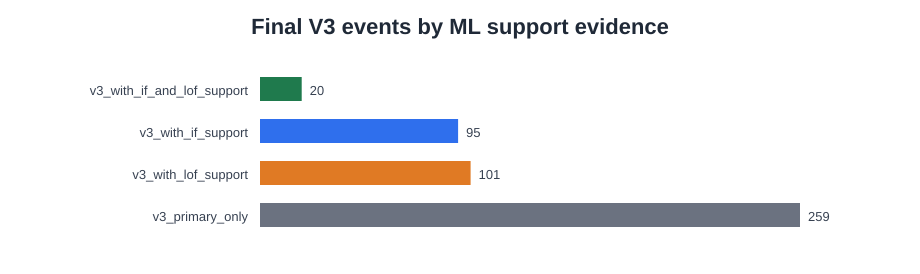

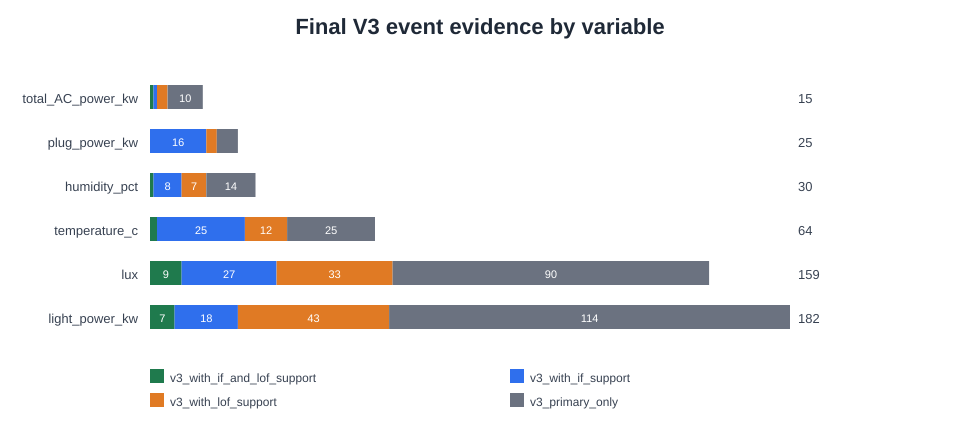

,chart,path,use
0,Final event evidence levels,outputs\floor6_zone1245_final_v3_with_ml_suppo...,Shows how many final V3 events are supported b...
1,Final event evidence by variable,outputs\floor6_zone1245_final_v3_with_ml_suppo...,Shows which sensor variables drive final V3 ev...


In [6]:
from html import escape

LEVEL_ORDER = [
    "v3_with_if_and_lof_support",
    "v3_with_if_support",
    "v3_with_lof_support",
    "v3_primary_only",
]
LEVEL_COLORS = {
    "v3_with_if_and_lof_support": "#1f7a4d",
    "v3_with_if_support": "#2f6fed",
    "v3_with_lof_support": "#e07a24",
    "v3_primary_only": "#6b7280",
}


def write_horizontal_bar_svg(data: pd.DataFrame, label_col: str, value_col: str, title: str, output_path: Path) -> Path:
    plot = data.copy()
    plot[value_col] = pd.to_numeric(plot[value_col], errors="coerce").fillna(0)
    width = 920
    row_h = 42
    margin_left = 260
    margin_right = 120
    margin_top = 70
    margin_bottom = 36
    height = margin_top + margin_bottom + row_h * len(plot)
    plot_w = width - margin_left - margin_right
    max_value = max(float(plot[value_col].max()), 1.0)
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="{escape(title)}">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="{width/2}" y="34" text-anchor="middle" font-family="Arial" font-size="22" font-weight="700" fill="#1f2937">{escape(title)}</text>',
    ]
    for i, row in plot.reset_index(drop=True).iterrows():
        y = margin_top + i * row_h
        label = str(row[label_col])
        value = float(row[value_col])
        bar_w = value / max_value * plot_w
        color = LEVEL_COLORS.get(label, "#2f6fed")
        parts.append(f'<text x="{margin_left - 12}" y="{y + 25}" text-anchor="end" font-family="Arial" font-size="13" fill="#374151">{escape(label)}</text>')
        parts.append(f'<rect x="{margin_left}" y="{y + 7}" width="{bar_w:.1f}" height="24" fill="{color}"/>')
        parts.append(f'<text x="{margin_left + bar_w + 8}" y="{y + 25}" font-family="Arial" font-size="13" fill="#374151">{int(value)}</text>')
    parts.append('</svg>')
    output_path.write_text("\n".join(parts), encoding="utf-8")
    return output_path


def write_stacked_variable_svg(data: pd.DataFrame, output_path: Path) -> Path:
    pivot = (
        data.pivot_table(index="variable", columns="final_evidence_level", values="event_count", aggfunc="sum", fill_value=0)
        .reindex(columns=LEVEL_ORDER, fill_value=0)
    )
    pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=True).index]
    width = 960
    row_h = 44
    margin_left = 150
    margin_right = 170
    margin_top = 78
    margin_bottom = 86
    height = margin_top + margin_bottom + row_h * len(pivot)
    plot_w = width - margin_left - margin_right
    max_total = max(float(pivot.sum(axis=1).max()), 1.0)
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="Final V3 event evidence by variable">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="{width/2}" y="34" text-anchor="middle" font-family="Arial" font-size="22" font-weight="700" fill="#1f2937">Final V3 event evidence by variable</text>',
    ]
    for i, (variable, row) in enumerate(pivot.iterrows()):
        y = margin_top + i * row_h
        x = margin_left
        total = int(row.sum())
        parts.append(f'<text x="{margin_left - 12}" y="{y + 25}" text-anchor="end" font-family="Arial" font-size="13" fill="#374151">{escape(str(variable))}</text>')
        for level in LEVEL_ORDER:
            value = int(row[level])
            if value == 0:
                continue
            w = value / max_total * plot_w
            parts.append(f'<rect x="{x:.1f}" y="{y + 7}" width="{w:.1f}" height="24" fill="{LEVEL_COLORS[level]}"/>')
            if w > 22:
                parts.append(f'<text x="{x + w/2:.1f}" y="{y + 24}" text-anchor="middle" font-family="Arial" font-size="11" fill="white">{value}</text>')
            x += w
        parts.append(f'<text x="{margin_left + plot_w + 8}" y="{y + 25}" font-family="Arial" font-size="13" fill="#374151">{total}</text>')
    legend_y = height - 46
    legend_x = margin_left
    for i, level in enumerate(LEVEL_ORDER):
        x = legend_x + (i % 2) * 360
        y = legend_y + (i // 2) * 24
        parts.append(f'<rect x="{x}" y="{y-13}" width="14" height="14" fill="{LEVEL_COLORS[level]}"/>')
        parts.append(f'<text x="{x+20}" y="{y}" font-family="Arial" font-size="12" fill="#374151">{escape(level)}</text>')
    parts.append('</svg>')
    output_path.write_text("\n".join(parts), encoding="utf-8")
    return output_path


evidence_for_chart = event_evidence_summary.copy()
evidence_for_chart["sort_rank"] = evidence_for_chart["final_evidence_level"].map({level: i for i, level in enumerate(LEVEL_ORDER)})
evidence_for_chart = evidence_for_chart.sort_values("sort_rank")
evidence_chart = write_horizontal_bar_svg(
    evidence_for_chart,
    "final_evidence_level",
    "event_count",
    "Final V3 events by ML support evidence",
    CHART_DIR / "01_final_event_evidence_levels.svg",
)
variable_chart = write_stacked_variable_svg(
    variable_evidence_summary,
    CHART_DIR / "02_final_event_evidence_by_variable.svg",
)

chart_index = pd.DataFrame([
    {
        "chart": "Final event evidence levels",
        "path": str(evidence_chart.relative_to(PROJECT_DIR)),
        "use": "Shows how many final V3 events are supported by IF and/or LOF.",
    },
    {
        "chart": "Final event evidence by variable",
        "path": str(variable_chart.relative_to(PROJECT_DIR)),
        "use": "Shows which sensor variables drive final V3 events and their ML support level.",
    },
])
chart_index.to_csv(OUTPUT_DIR / "07_final_model_chart_index.csv", index=False)

display(Markdown("## Final model charts"))
display(SVG(filename=str(evidence_chart)))
display(SVG(filename=str(variable_chart)))
display(chart_index)


## Cell 7：写出最终模型选择说明

这个 cell 会生成可以直接放进报告的方法结论文本。文本会明确说明：V3 是最终/主模型，而 Optimized Isolation Forest 和 LOF 是辅助的无监督机器学习支持证据。

这段文字可以用于报告的 methodology 或 results 部分。

**输出文件：**

- `08_final_model_selection_statement.md`
- `final_model_selection_summary.json`

In [7]:
method_selection = json.loads(METHOD_SELECTION_PATH.read_text(encoding="utf-8"))
strong_count = int(final_events["final_evidence_level"].eq("v3_with_if_and_lof_support").sum())
if_count = int(final_events["if_meaningful_support"].sum())
lof_count = int(final_events["lof_meaningful_support"].sum())
primary_only_count = int(final_events["final_evidence_level"].eq("v3_primary_only").sum())
total_events = int(len(final_events))

report_text = f"""
## Final Modelling Strategy

The final model for the project is the **V3 operation-aware statistical baseline**. It is used to define the final anomaly labels, final anomaly events, event severity, variable-level explanations, and subsequent analysis outputs.

The unsupervised machine-learning models are retained as supporting evidence rather than replacing the final model. **Optimized Isolation Forest** is the primary ML support model, because it was the strongest unsupervised ML method in the budget-controlled method evaluation. **LOF** is kept as an additional benchmark.

In the final V3 event table, there are **{total_events}** V3 anomaly events. **{if_count}** events have meaningful Isolation Forest support, **{lof_count}** events have meaningful LOF support, and **{strong_count}** events have support from both IF and LOF. The remaining **{primary_only_count}** events are still final anomalies because the final model is V3, but they should be interpreted as V3-primary events without strong ML corroboration.

This combined design satisfies the project aim of using AI for smart-building log analysis while keeping the final outputs interpretable. V3 provides the operational explanation; IF and LOF provide AI/ML-based cross-model evidence and benchmarking.
""".strip()

selection_payload = {
    "final_main_model": "V3 operation-aware statistical baseline",
    "final_main_model_role": "Defines final anomaly labels, final events, severity, and explanations.",
    "primary_supporting_ml_model": "Optimized Isolation Forest",
    "secondary_supporting_ml_model": "LOF",
    "support_threshold": {
        "min_points": MIN_MEANINGFUL_SUPPORT_POINTS,
        "min_event_pct": MIN_MEANINGFUL_SUPPORT_PCT,
    },
    "v3_event_count": total_events,
    "if_supported_event_count": if_count,
    "lof_supported_event_count": lof_count,
    "if_and_lof_supported_event_count": strong_count,
    "v3_primary_only_event_count": primary_only_count,
    "method_selection_reference": method_selection,
}

(OUTPUT_DIR / "08_final_model_selection_statement.md").write_text(report_text + "\n", encoding="utf-8")
(OUTPUT_DIR / "final_model_selection_summary.json").write_text(
    json.dumps(selection_payload, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

display(Markdown(report_text))
display(pd.DataFrame([selection_payload]).T.rename(columns={0: "value"}))


## Final Modelling Strategy

The final model for the project is the **V3 operation-aware statistical baseline**. It is used to define the final anomaly labels, final anomaly events, event severity, variable-level explanations, and subsequent analysis outputs.

The unsupervised machine-learning models are retained as supporting evidence rather than replacing the final model. **Optimized Isolation Forest** is the primary ML support model, because it was the strongest unsupervised ML method in the budget-controlled method evaluation. **LOF** is kept as an additional benchmark.

In the final V3 event table, there are **475** V3 anomaly events. **115** events have meaningful Isolation Forest support, **121** events have meaningful LOF support, and **20** events have support from both IF and LOF. The remaining **259** events are still final anomalies because the final model is V3, but they should be interpreted as V3-primary events without strong ML corroboration.

This combined design satisfies the project aim of using AI for smart-building log analysis while keeping the final outputs interpretable. V3 provides the operational explanation; IF and LOF provide AI/ML-based cross-model evidence and benchmarking.

,value
final_main_model,V3 operation-aware statistical baseline
final_main_model_role,"Defines final anomaly labels, final events, se..."
primary_supporting_ml_model,Optimized Isolation Forest
secondary_supporting_ml_model,LOF
support_threshold,"{'min_points': 5, 'min_event_pct': 5.0}"
v3_event_count,475
if_supported_event_count,115
lof_supported_event_count,121
if_and_lof_supported_event_count,20
v3_primary_only_event_count,259


## Cell 8：验证输出并列出生成文件

最后这个 cell 会进行 sanity checks，确认 notebook 的最终输出是完整且一致的。它会检查：

- 所有 V3 事件都被保留下来
- 所有 final events 仍然是 V3 异常
- 逐分钟证据标签没有缺失
- LOF 对齐正确
- 图表文件已经生成

如果任何验证失败，notebook 会直接报错。如果所有检查通过，它会列出所有生成的最终模型输出文件。

In [8]:
validations = []
validations.append({"check": "v3_events_preserved", "passed": len(final_events) == len(v3_events), "evidence": f"events={len(final_events)}"})
validations.append({"check": "all_final_events_are_v3", "passed": final_events["final_anomaly_label"].eq(1).all(), "evidence": "final_anomaly_label=1 for every event"})
validations.append({"check": "row_labels_available", "passed": not point_evidence[point_output_cols].isna().any().any(), "evidence": f"rows={len(point_evidence)}"})
validations.append({"check": "lof_alignment", "passed": np.isclose(lof_label_agreement, 1.0), "evidence": f"agreement={lof_label_agreement:.6f}"})
validations.append({"check": "chart_files_created", "passed": evidence_chart.is_file() and variable_chart.is_file(), "evidence": "2 SVG charts"})
validation_df = pd.DataFrame(validations)
validation_df.to_csv(OUTPUT_DIR / "09_validation_checks.csv", index=False)
if not validation_df["passed"].all():
    raise AssertionError(validation_df.loc[~validation_df["passed"]].to_dict(orient="records"))

display(validation_df)
print("Generated final-model outputs:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_DIR))


,check,passed,evidence
0,v3_events_preserved,True,events=475
1,all_final_events_are_v3,True,final_anomaly_label=1 for every event
2,row_labels_available,True,rows=362880
3,lof_alignment,True,agreement=1.000000
4,chart_files_created,True,2 SVG charts


Generated final-model outputs:
outputs\floor6_zone1245_final_v3_with_ml_support\01_final_v3_events_with_ml_support.csv
outputs\floor6_zone1245_final_v3_with_ml_support\02_final_event_evidence_summary.csv
outputs\floor6_zone1245_final_v3_with_ml_support\03_final_event_evidence_by_variable.csv
outputs\floor6_zone1245_final_v3_with_ml_support\04_final_event_evidence_by_anomaly_method.csv
outputs\floor6_zone1245_final_v3_with_ml_support\05_final_point_evidence_labels.csv.gz
outputs\floor6_zone1245_final_v3_with_ml_support\06_final_point_evidence_summary.csv
outputs\floor6_zone1245_final_v3_with_ml_support\07_final_model_chart_index.csv
outputs\floor6_zone1245_final_v3_with_ml_support\08_final_model_selection_statement.md
outputs\floor6_zone1245_final_v3_with_ml_support\09_validation_checks.csv
outputs\floor6_zone1245_final_v3_with_ml_support\charts\01_final_event_evidence_levels.svg
outputs\floor6_zone1245_final_v3_with_ml_support\charts\02_final_event_evidence_by_variable.svg
outputs\floo